<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [FRED and ALFRED](https://github.com/Query-farm/vgi-fred)

Economic observations, historical vintages, revision intervals and discovery metadata.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-fred/blob/main/notebooks/02_search_rank_is_not_comparability.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-fred/blob/main/notebooks/README.md)


## 02 · A highly ranked search hit can still be the wrong comparison

Which synthetic “output” series belongs on a quarterly nominal-level shortlist?
We use a known series to locate its category, retrieve that category and a broader
text search, then separate **membership**, **measurement definition** and a selected
**popularity threshold**. Popularity ranks attention; it does not establish validity.

All six series, titles, categories and scores below are **authored synthetic metadata**,
not recorded FRED responses. Familiar symbols are fixture routing keys. A local
read-only HTTP service supplies the documented response shapes to the real released
worker. No economic observations are retrieved, and no conclusion describes the US
economy or proves that retained series are interchangeable.

### Change only the shortlist threshold

The default `MIN_POPULARITY = 80` becomes **40** in the experiment. The complete search,
category membership and metadata remain fixed. Lowering this attention threshold can
add candidates, but cannot repair incompatible units, frequency or adjustment.
The target definition is **Quarterly**, **Billions of US dollars**, **Seasonally adjusted
annual rate**; even matching these fields still requires substantive definition review.

In [1]:
MIN_POPULARITY = 80  # Experiment: 40; integer from 0 through 100.

### Run this notebook

Read saved results on GitHub, or choose **Open in Colab** and Run All. The compact setup
installs only the shared base tools and preserves compatible preloaded data/plotting
libraries. Packages, verified companions, the VGI extension and released Git worker
need initial internet access; analytical retrieval then uses only an ephemeral
`127.0.0.1` fixture. uv manages the worker's separate Python 3.13+ environment.

A fresh preloaded Python 3.12 notebook-only run checks this installation path;
actual hosted Colab has not been tested. No checkout, real API key or live account
is needed. The reader can configure official FRED separately using the root README;
these examples never silently switch to a real endpoint.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.28":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.28"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.28":
    raise RuntimeError("Install shared tools v0.3.28, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("fred")
%matplotlib inline
theme()
session = connect(globals())
con = session.connection

from discovery_fixture import DiscoveryFixture

fixture = DiscoveryFixture(MIN_POPULARITY)
candidates = funnel = pd.DataFrame()
source = "Authored synthetic metadata · local fixture only · FRED v0.1.0 · fixed 2021-03-31"

### Attach the released worker to isolated fixture credentials

The shared session opens an empty temporary SQL-secret directory with persistence
disabled. The helper clears inherited FRED credentials and endpoint settings, then
points the worker at its ephemeral loopback server. Only the public all-zero fake
key below is accepted. Every read is materialized once before display; later SQL and
plots query local tables. Cleanup verifies temporary-only storage, drops the secret,
closes the session and server, and restores the prior environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'fred' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-fred@v0.1.0 vgi-fred-worker');
CREATE TEMPORARY SECRET fred_fixture
 (TYPE fred_api, API_KEY '00000000000000000000000000000000');
SELECT name, persistent, storage FROM duckdb_secrets();

,name,persistent,storage
0,fred_fixture,False,memory


In [5]:
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [
    ("fred_fixture", False, "memory")
]

### Resolve a category instead of guessing from the series name

Browse the root's immediate children, ask which category contains the seed `GDP`,
and retrieve category 125's own parent and description. The intersection gives a
checked navigation path, rather than treating a hard-coded category ID as a match.
It is a direct parent/child check, not a recursive traversal of the real FRED catalog.

In [6]:
%%sql
CREATE TABLE root_children AS SELECT * FROM fred.main.category_children(0,
 realtime_start := '2021-03-31', realtime_end := '2021-03-31');
CREATE TABLE seed_categories AS SELECT * FROM fred.main.series_categories('GDP',
 realtime_start := '2021-03-31', realtime_end := '2021-03-31');
CREATE TABLE selected_category AS SELECT * FROM fred.main.category(125);
CREATE TABLE navigation AS
SELECT c.id,c.name,c.parent_id,c.notes,
 EXISTS(SELECT 1 FROM root_children r WHERE r.id=c.id AND r.parent_id=c.parent_id) AS root_child,
 EXISTS(SELECT 1 FROM seed_categories s WHERE s.id=c.id) AS contains_seed
FROM selected_category c;
SELECT * FROM navigation;

,id,name,parent_id,notes,root_child,contains_seed
0,125,National output (synthetic),0,Contains five fixture series; category members...,True,True


### Fetch complete fixture populations before imposing a shortlist

`category_series` returns five members; `search_series` returns six hits sorted by
popularity. Page size two forces three requests for each paginated endpoint.
The explicit real-time window fixes the metadata snapshot. We do not cap `max_rows`:
otherwise a missing candidate might mean a truncated search, not incompatibility.
The exact HTTP audit will check page offsets and ensure displays add no requests.

In [7]:
%%sql
CREATE TABLE category_members AS SELECT * FROM fred.main.category_series(125,
 realtime_start := '2021-03-31', realtime_end := '2021-03-31', page_size := 2);
CREATE TABLE search_hits AS SELECT * FROM fred.main.search_series('output',
 order_by := 'popularity', sort_order := 'desc',
 realtime_start := '2021-03-31', realtime_end := '2021-03-31', page_size := 2);
SELECT id,title,popularity,frequency,units,seasonal_adjustment
FROM search_hits ORDER BY popularity DESC,id;

,id,title,popularity,frequency,units,seasonal_adjustment
0,GDPX,External output measure (synthetic),99,Quarterly,Billions of US dollars,Seasonally adjusted annual rate
1,RGDP,Real domestic product (synthetic),95,Quarterly,Billions of chained dollars,Seasonally adjusted annual rate
2,GDP,Gross domestic product (synthetic),90,Quarterly,Billions of US dollars,Seasonally adjusted annual rate
3,MGDP,Monthly activity indicator (synthetic),85,Monthly,Billions of US dollars,Seasonally adjusted annual rate
4,GDPNSA,Unadjusted domestic product (synthetic),70,Quarterly,Billions of US dollars,Not seasonally adjusted
5,GDI,Gross domestic income (synthetic),60,Quarterly,Billions of US dollars,Seasonally adjusted annual rate


### Keep failed criteria visible, and do not add unlike measures

A left join retains every search hit, including the one outside the selected category.
Separate boolean fields expose each criterion; no measure is rescaled to make it fit.
The cumulative funnel first checks membership, then the three definition fields,
then the popularity threshold. A rejected item can fail more than one criterion;
the matrix shows individual checks while the funnel shows sequential counts.

In [8]:
%%sql
CREATE TABLE candidate_checks AS
SELECT s.id,s.title,s.popularity,s.frequency,s.units,s.seasonal_adjustment,
 c.id IS NOT NULL AS in_category,
 s.frequency = 'Quarterly' AS quarterly,
 s.units = 'Billions of US dollars' AS nominal_usd_bn,
 s.seasonal_adjustment = 'Seasonally adjusted annual rate' AS saar,
 s.popularity >= {{ MIN_POPULARITY }} AS above_threshold
FROM search_hits s LEFT JOIN category_members c USING(id);
CREATE TABLE candidates AS SELECT *,
 in_category AND quarterly AND nominal_usd_bn AND saar AS definition_match,
 in_category AND quarterly AND nominal_usd_bn AND saar AND above_threshold AS shortlisted
FROM candidate_checks;
CREATE TABLE funnel AS
SELECT 1 AS step,'Search hits' AS stage,count(*) AS count FROM candidates
UNION ALL SELECT 2,'In selected category',count(*) FROM candidates WHERE in_category
UNION ALL SELECT 3,'Definition matches',count(*) FROM candidates WHERE definition_match
UNION ALL SELECT 4,'Above selected threshold',count(*) FROM candidates WHERE shortlisted;
SELECT id,popularity,in_category,quarterly,nominal_usd_bn,saar,above_threshold,shortlisted
FROM candidates ORDER BY popularity DESC,id;

,id,popularity,in_category,quarterly,nominal_usd_bn,saar,above_threshold,shortlisted
0,GDPX,99,False,True,True,True,True,False
1,RGDP,95,True,True,False,True,True,False
2,GDP,90,True,True,True,True,True,True
3,MGDP,85,True,False,True,True,True,False
4,GDPNSA,70,True,True,True,False,False,False
5,GDI,60,True,True,True,True,False,False


In [9]:
%%sql candidates <<
SELECT * FROM candidates ORDER BY popularity DESC,id;

In [10]:
%%sql funnel <<
SELECT * FROM funnel ORDER BY step;

In [11]:
navigation = con.execute("SELECT * FROM navigation").fetchdf().iloc[0]
assert navigation.root_child and navigation.contains_seed
selected = candidates.loc[candidates.shortlisted, "id"].tolist()
prose(
    f"The seed belongs to **{navigation['name']}**, category **{navigation.id}**, a checked child of root 0. "
    f"The search has **{len(candidates)} hits**; "
    f"**{int(candidates.in_category.sum())}** belong to the category "
    f"and **{int(candidates.definition_match.sum())}** match all three definition fields. "
    f"At popularity ≥ **{MIN_POPULARITY}**, the shortlist contains **{len(selected)}** series: "
    f"**{', '.join(selected) if selected else 'none'}**. GDPX, the top hit, is outside the category; "
    "RGDP uses chained-dollar units, MGDP is monthly and GDPNSA is unadjusted. "
    "GDP and GDI pass this metadata screen, but describe different accounting concepts: this is a "
    "review queue, not permission to add, substitute or causally compare their values."
)

The seed belongs to **National output (synthetic)**, category **125**, a checked child of root 0. The search has **6 hits**; **5** belong to the category and **2** match all three definition fields. At popularity ≥ **80**, the shortlist contains **1** series: **GDP**. GDPX, the top hit, is outside the category; RGDP uses chained-dollar units, MGDP is monthly and GDPNSA is unadjusted. GDP and GDI pass this metadata screen, but describe different accounting concepts: this is a review queue, not permission to add, substitute or causally compare their values.

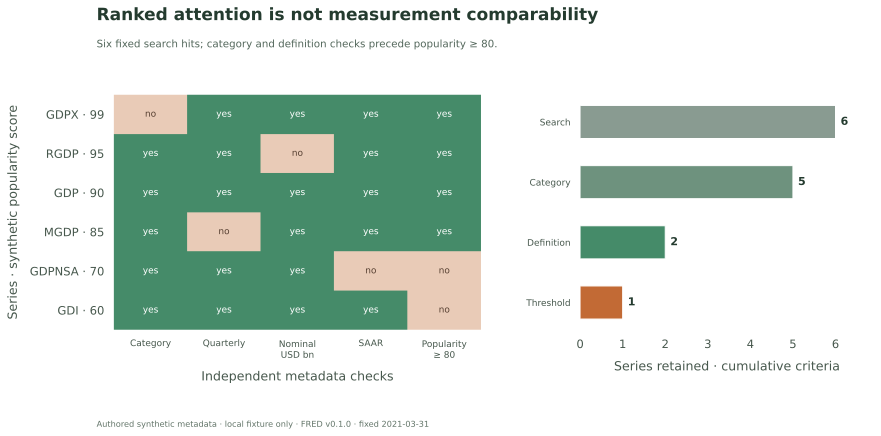

In [12]:
from matplotlib.colors import ListedColormap

columns = ["in_category", "quarterly", "nominal_usd_bn", "saar", "above_threshold"]
labels = ["Category", "Quarterly", "Nominal\nUSD bn", "SAAR", f"Popularity\n≥ {MIN_POPULARITY}"]
fig, (ax, bar) = plt.subplots(1, 2, figsize=(12.0, 6.4), gridspec_kw={"width_ratios": [1.25, 1]})
matrix = candidates[columns].to_numpy(dtype=int)
ax.imshow(matrix, cmap=ListedColormap(["#E9CBB7", "#458B69"]), vmin=0, vmax=1, aspect="auto")
for row in range(len(candidates)):
    for col in range(len(columns)):
        ax.text(
            col,
            row,
            "yes" if matrix[row, col] else "no",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if matrix[row, col] else "#563F31",
        )
ax.set_yticks(range(len(candidates)), [f"{row.id} · {row.popularity}" for row in candidates.itertuples()])
ax.set_xticks(range(len(columns)), labels, fontsize=9)
ax.set_ylabel("Series · synthetic popularity score")
ax.set_xlabel("Independent metadata checks")
y = np.arange(len(funnel))
bar.barh(y, funnel["count"], color=["#899B91", "#6E927E", "#458B69", "#C26A35"], height=0.55)
bar.invert_yaxis()
bar.set_yticks(y, ["Search", "Category", "Definition", "Threshold"], fontsize=9)
bar.set_xlim(0, 6.9)
bar.set_xticks(range(7))
bar.set_xlabel("Series retained · cumulative criteria")
for i, value in enumerate(funnel["count"]):
    bar.text(value + 0.12, i, str(value), va="center", fontweight="bold")
fig.subplots_adjust(wspace=0.8)
finish(
    fig,
    "Ranked attention is not measurement comparability",
    f"Six fixed search hits; category and definition checks precede popularity ≥ {MIN_POPULARITY}.",
    source,
    name=f"discovery-screen-{MIN_POPULARITY}",
)

### Check population accounting and the actual HTTP boundary

The seven checks below cover complete fixture populations, unique identifiers,
verified category navigation, nested filters and the independent expected shortlist.
The request audit requires exactly nine GETs: three category/navigation calls and
six pages. It validates the fixed metadata window and records no credential values.
Transport completeness here concerns this fixture, not all series in official FRED.

In [13]:
%%sql checks <<
SELECT 'Six unique search hits' AS invariant,count(*)=6 AND count(DISTINCT id)=6 AS passed FROM search_hits
UNION ALL SELECT 'Five unique category members',count(*)=5 AND count(DISTINCT id)=5 FROM category_members
UNION ALL SELECT 'Navigation includes the seed and its parent',count(*)=1 AND bool_and(root_child AND contains_seed AND parent_id=0) FROM navigation
UNION ALL SELECT 'Two compatible definitions',count(*)=2 FROM candidates WHERE definition_match
UNION ALL SELECT 'Filters never add series',min(delta)>=0 FROM (SELECT count-lag(count,1,count) OVER(ORDER BY step DESC) AS delta FROM funnel)
UNION ALL SELECT 'Shortlist matches the independent fixture expectation',
 coalesce(list(id ORDER BY id),[])=(SELECT coalesce(list(id ORDER BY id),[])
 FROM (VALUES ('GDP',90),('GDI',60)) expected(id,score) WHERE score >= {{ MIN_POPULARITY }})
 FROM candidates WHERE shortlisted
UNION ALL SELECT 'All metadata has the fixed knowledge date',
 bool_and(realtime_start=DATE '2021-03-31' AND realtime_end=DATE '2021-03-31') FROM search_hits;

In [14]:
display(checks)
assert len(checks) == 7 and checks.passed.all()
requests = fixture.audit()
prose(
    f"All **{len(checks)} SQL checks** pass. The released worker made exactly **{requests} local GETs**; "
    "captured tables and the figure added none. No real FRED service or key was used."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/discovery-audit.json").write_text(
    json.dumps(
        {
            "minimum_popularity": MIN_POPULARITY,
            "requests": requests,
            "candidates": candidates.to_dict("records"),
            "funnel": funnel.to_dict("records"),
            "navigation": con.execute("SELECT * FROM navigation").fetchdf().to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
        default=str,
    )
)

,invariant,passed
0,Six unique search hits,True
1,Five unique category members,True
2,Navigation includes the seed and its parent,True
3,Two compatible definitions,True
4,Filters never add series,True
5,Shortlist matches the independent fixture expe...,True
6,All metadata has the fixed knowledge date,True


All **7 SQL checks** pass. The released worker made exactly **9 local GETs**; captured tables and the figure added none. No real FRED service or key was used.

4004

### Experiment: lower attention, keep definitions fixed

Run a separate copy with `MIN_POPULARITY = 40`. Predict that GDI joins GDP while
GDPX, RGDP, MGDP and GDPNSA remain excluded. All six retrieved rows, five category
members, navigation and nine HTTP requests must remain identical. Only the final
threshold flags and shortlist change. This is a screening-policy experiment, not
an evaluation of real popularity, economic quality or predictive performance.
Exact protected runner commands and live-service configuration guidance are in README.md.

In [15]:
assert con.execute("SELECT name, persistent, storage FROM duckdb_secrets()").fetchall() == [
    ("fred_fixture", False, "memory")
]
con.execute("DROP SECRET fred_fixture")
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
fixture.stop()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-fred](https://github.com/Query-farm/vgi-fred)